# Self Organising Maps

Using self-organising maps to visualise the feature space (NOT IMPLEMENTED)

In [177]:
import sys

In [178]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [179]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 25E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.001

wavelet = "db20"
levels = 4
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots


### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.


In [187]:
wpt_df = None
for frequency in [i * 1E5 for i in range(3, 15)]:
    for pac in [-i * 1E4 for i in range(1, 20)]:
        data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
            continue
        data = (data - np.mean(data))/np.std(data)
        data += np.random.normal(0, std_noise, size=len(data))

        # data = np.random.normal(0, std_noise, size=len(data))

        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = train.generate_training_data(
            data[::step], levels, wavelet, mode, min_energy=0.005, 
            include_low_energy=0, print_nodes_kept=False
        )
        if wpt_df is None:
            wpt_df = training_data
        else:
            wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

# Add noise samples
add_noise = .1  # 1/10 of the dataset is noise
n = wpt_df.shape[0]
n_noise_samples = int(n * add_noise / (1 - add_noise))

for i in range(n_noise_samples):
    noise = np.random.normal(0, std_noise, size=len(data))
    training_data = train.generate_training_data(noise[::step], levels, wavelet, mode)
    wpt_df= pd.concat([wpt_df, training_data], ignore_index=True)

### Training

Train algorithm on the generated data

In [181]:
n_data_points = wpt_df.shape[0]
print(n_data_points)
n_neurons = 5 * n_data_points ** (1 / 2)
print(n_neurons)

853
146.03081866510234


### Feature selection

In [185]:
from sklearn.preprocessing import StandardScaler
from sklearn_som.som import SOM

# Get data, select which features to analyse
classifying_metrics = [
    "energy",
    # "log energy",
    # "spectral entropy",
    "entropy",
    # "crest factor",
    # "abs skewness",
    "kurtosis",
    # "level entropy",
]
n_metrics = len(classifying_metrics)
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Self organising maps
som_rows = 12
som_size = (som_rows, int(n_neurons / som_rows))  # set size
som_width, som_height = som_size
n_clusters = som_width * som_height
som = SOM(som_width, som_height, n_metrics)
labels = som.fit_predict(data_train_normalised)

# Cluster centres
centers = som.cluster_centers_
# display(centers)
centers = som.cluster_centers_.reshape((n_clusters, n_metrics))
# print(centers)
centers = scaler.inverse_transform(centers)

# print("centers:", centers)

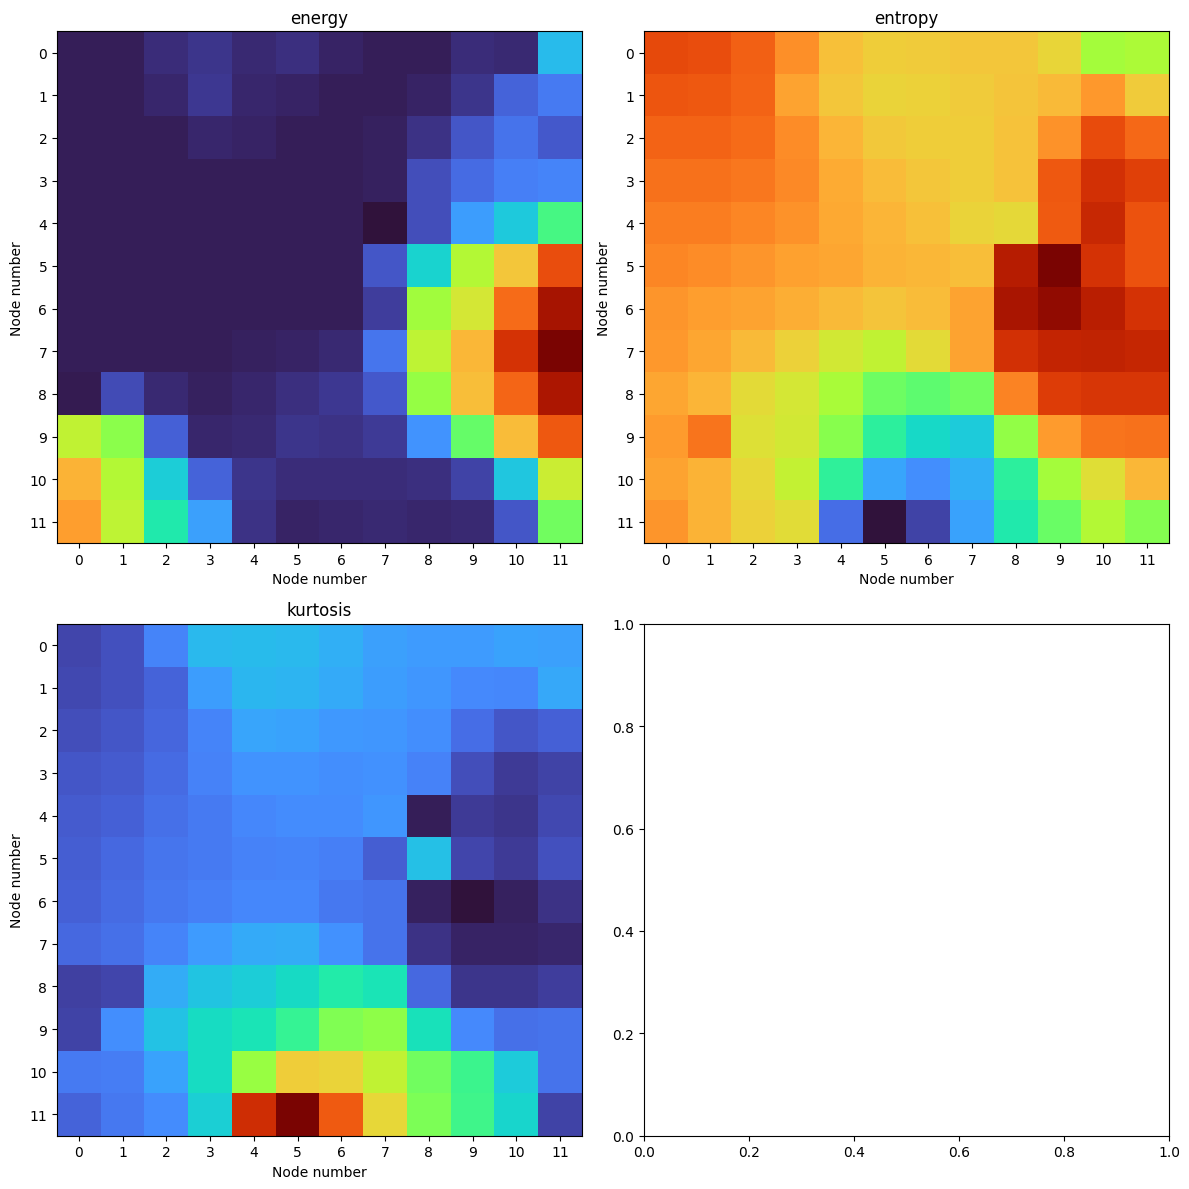

In [186]:
# Plotting heatmaps for each feature
columns = 2
rows = n_metrics / columns
if rows.is_integer() is False:
    rows = int(rows) + 1# round up if there aren't enough rows
rows = max(2, rows)
fig, axes = plt.subplots(int(rows), columns, figsize=(12, 12))

for i, feature in enumerate(classifying_metrics):
    row, col = i // columns, i % columns
    feature_values = centers[:, i].reshape(som_size[::-1])
    # print(centers[:, i])
    ax:plt.Axes = axes[row, col]
    ax.imshow(feature_values, cmap='turbo', aspect='auto')
    ax.set_title(f'{feature}')
    ax.set_xlabel("Node number")
    ax.set_ylabel("Node number")
    ax.set_xticks(range(som_width))
    ax.set_yticks(range(som_height))

plt.tight_layout()
plt.show()

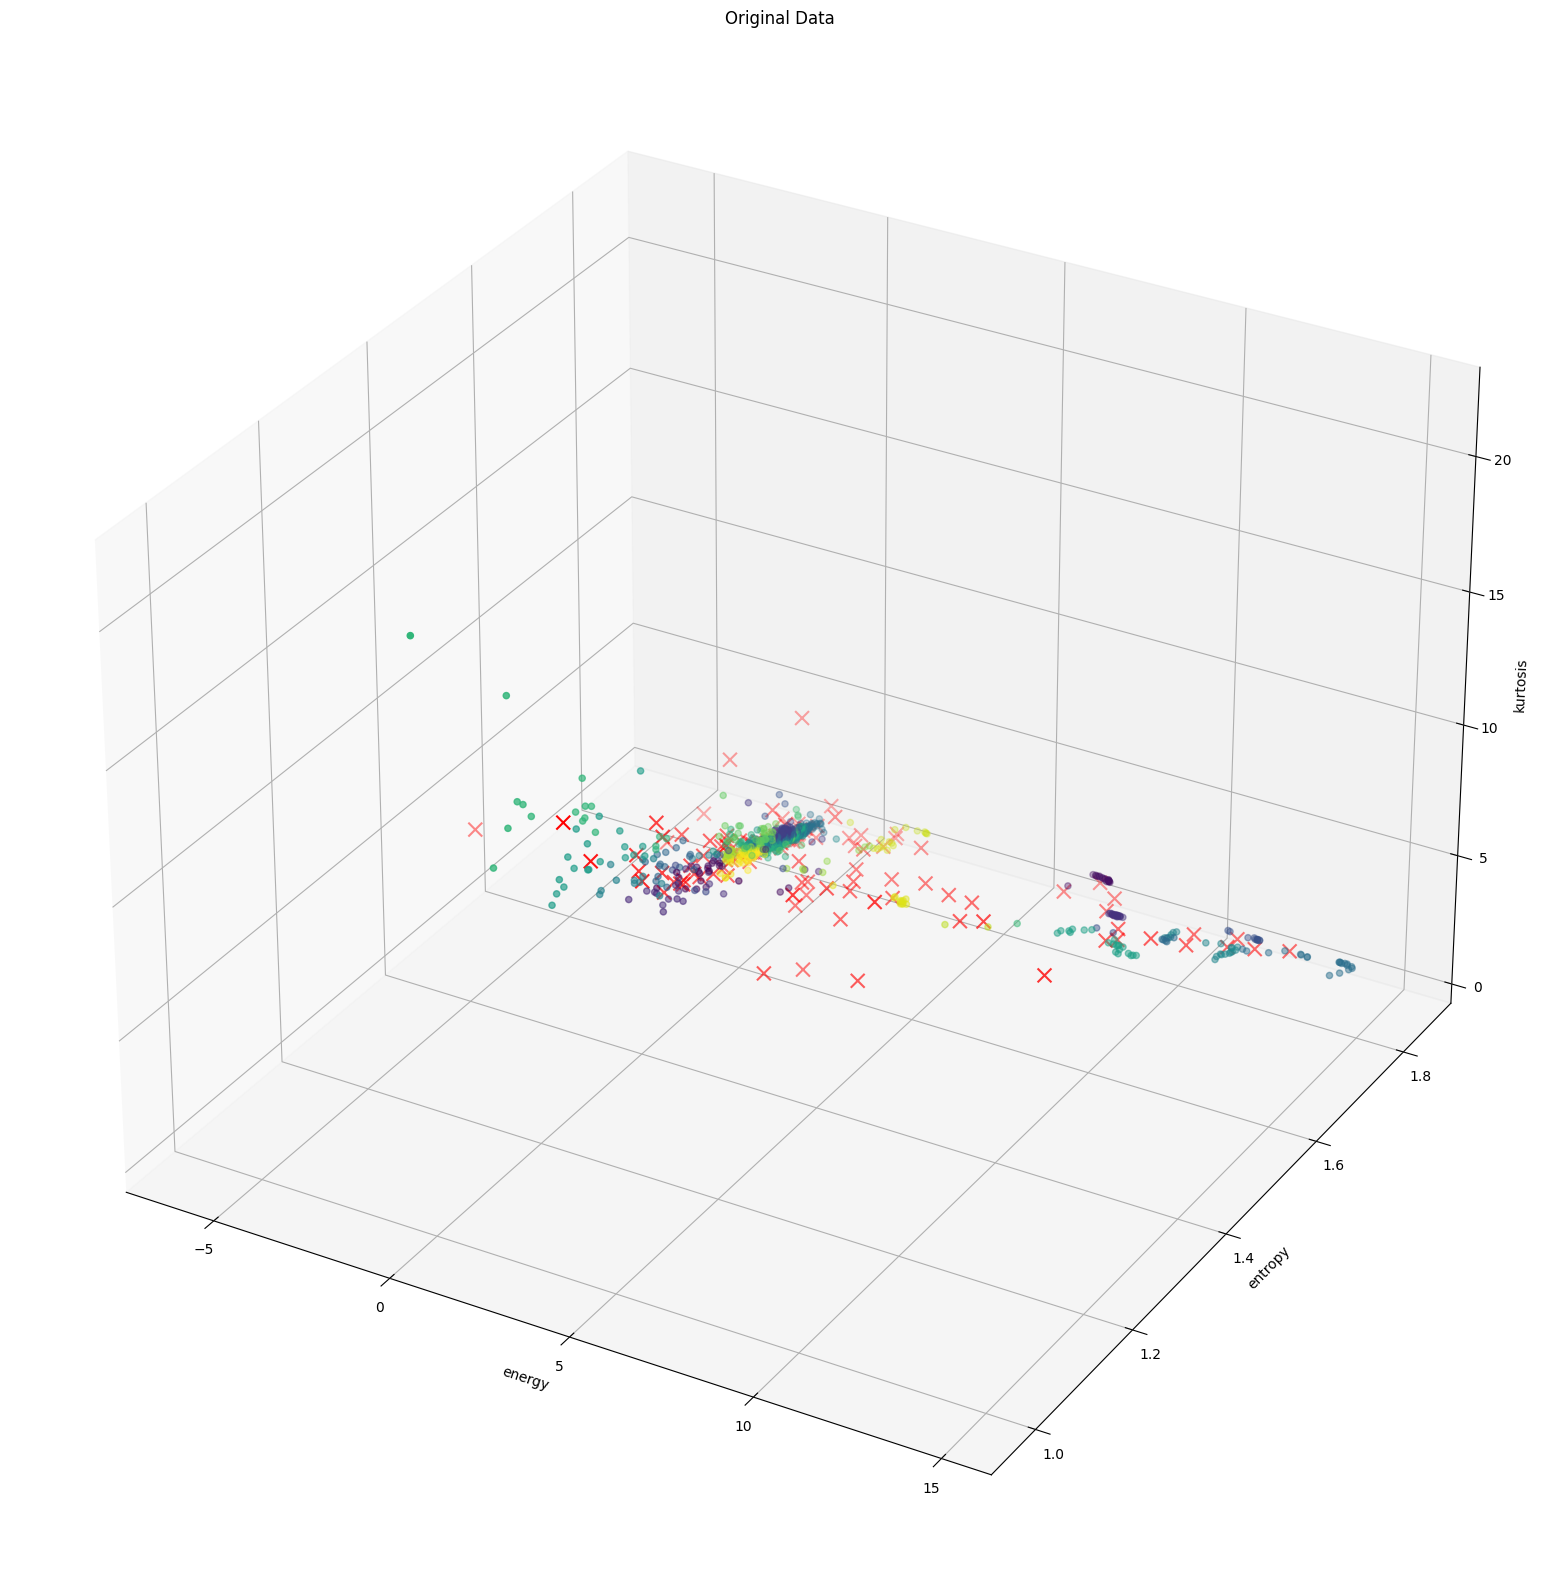

In [184]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()